# RNAP Hack 2026 · Redes Neuronales y Aprendizaje Profundo
## Reporte Técnico de Entrenamiento
**UANL · Escuela Industrial y Preparatoria Técnica "Álvaro Obregón"**  
**Equipo:** `cepesin_chuy` | **Fecha:** Jueves 5 de Noviembre de 2026 | **Checkpoint:** `CP2` (Fase 1: Línea Base)

---
### Estructura del Reporte Técnico (Cuaderno de Entrenamiento)
| Sección | Contenido | Fase Evaluada |
|---|---|---|
| **1. Problema y datos** | Reto elegido, justificación, fuente, tamaño, división Train/Val/Test | **Fase 1 (Hoy)** |
| **2. Representación del texto** | Tokenización y representación usadas (TF-IDF vs Contextual) y justificación | **Fase 1 (Hoy)** |
| **3. Modelo base y preentrenado sin ajuste** | Configuración, entrenamiento, evaluación en prueba, tabla comparativa y conclusión | **Fase 1 (Hoy)** |
| **4. Solución con Transformer** | Modelo Transformer elegido, hiperparámetros y fine-tuning | *Fase 2 (12-Nov)* |
| **5. Evaluación y errores** | Métricas en prueba, gráficas y análisis de al menos 5 casos de error | *Fase 2 (12-Nov)* |
| **6. Comparación final y límites** | Comparación global, mecanismo de atención y límites del sistema | *Fase 3 (19-Nov)* |


---
# Sección 1. Problema y datos

### 1.1 Reto Elegido: Reto 1 · Human or Machine?
El reto seleccionado consiste en **diferenciar automáticamente textos escritos por humanos de textos generados por modelos de Inteligencia Artificial (LLMs) en idioma español**.

### 1.2 Importancia y Planteamiento del Problema
Con el auge vertiginoso de los modelos de lenguaje masivos (como GPT-3.5, GPT-4 y Llama), se ha vuelto fundamental contar con herramientas fiables capaces de verificar la autoría y la autenticidad de los contenidos textuales. Las aplicaciones prácticas abarcan:
1. **Integridad académica y educativa:** Prevenir el plagio automatizado y fomentar el desarrollo de habilidades críticas de redacción en estudiantes.
2. **Periodismo y combate a la desinformación:** Identificar artículos generados artificialmente a escala masiva para desinformar.
3. **Auditoría de propiedad intelectual:** Validar la procedencia de contenidos técnicos, literarios y corporativos.

### 1.3 Métrica Principal Elegida y Justificación
- **Métrica Principal:** **F1-Score (Macro)**.
- **Métricas Secundarias de Soporte:** **Exactitud (Accuracy)**, **Precisión (Precision)** y **Sensibilidad (Recall)**.

**Justificación Técnica de la Métrica:**  
En problemas de detección de autoría sintética, tanto los **Falsos Positivos** (acusar erróneamente a un estudiante de usar IA cuando escribió el texto legítimamente) como los **Falsos Negativos** (permitir que texto generado por IA pase desapercibido) conllevan graves consecuencias éticas y prácticas. El **F1-Score** representa la media armónica entre la Precisión y el Recall:
$$\text{F1-Score} = 2 \times \frac{\text{Precisión} \times \text{Recall}}{\text{Precisión} + \text{Recall}}$$
Al utilizar el promedio Macro, evaluamos el rendimiento equitativamente en ambas clases (Humano y Máquina) sin sesgo, asegurando un balance estricto y penalizando cualquier desproporción en los errores.

### 1.4 Fuente de los Datos y Tamaño del Dataset
Se recopiló y curó un corpus balanceado de **600 textos en español** con longitud promedio de entre 30 y 60 palabras por muestra, abarcando diversos dominios del conocimiento (ciencia, historia, tecnología, filosofía, cultura, literatura y vida cotidiana):
- **300 textos humanos (`label: 0`):** Extraídos de fuentes de acceso abierto, crónicas, literatura en español y reflexiones redactadas por hablantes nativos.
- **300 textos de máquina (`label: 1`):** Generados mediante modelos de lenguaje generativos en español, abarcando estilos explicativos, sintéticos y formales.

### 1.5 División en Entrenamiento, Validación y Prueba
Siguiendo las mejores prácticas de la disciplina y las instrucciones del hackatón, dividimos los datos **antes de iniciar cualquier fase de modelado**:
- **Entrenamiento (70%):** 420 muestras (210 humanos, 210 IA).
- **Validación (15%):** 90 muestras (45 humanos, 45 IA).
- **Prueba (15%):** 90 muestras (45 humanos, 45 IA).
Se aplicó **estratificación rigurosa** (`stratify=y`) con semilla fija (`random_state=42`) para garantizar que la proporción de clases sea idéntica en todas las particiones, evitando cualquier fuga de datos (*data leakage*).


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas de los subconjuntos procesados
data_dir = "../data" if os.path.exists("../data") else "data"
train_path = os.path.join(data_dir, "train.csv")
val_path = os.path.join(data_dir, "val.csv")
test_path = os.path.join(data_dir, "test.csv")

# Carga de particiones estratificadas
train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print(f"=== PARTICIONES DEL RETO: HUMAN OR MACHINE? ===")
print(f"Conjunto de Entrenamiento: {len(train_df)} muestras ({train_df['label'].value_counts().to_dict()})")
print(f"Conjunto de Validación:    {len(val_df)} muestras ({val_df['label'].value_counts().to_dict()})")
print(f"Conjunto de Prueba:        {len(test_df)} muestras ({test_df['label'].value_counts().to_dict()})")
print(f"Total del corpus:          {len(train_df) + len(val_df) + len(test_df)} muestras balanceadas")
print("\nEjemplo de texto humano (label 0):\n", train_df[train_df['label'] == 0]['text'].iloc[0])
print("\nEjemplo de texto generado por IA (label 1):\n", train_df[train_df['label'] == 1]['text'].iloc[0])


=== PARTICIONES DEL RETO: HUMAN OR MACHINE? ===
Conjunto de Entrenamiento: 420 muestras ({0: 210, 1: 210})
Conjunto de Validación:    90 muestras ({0: 45, 1: 45})
Conjunto de Prueba:        90 muestras ({0: 45, 1: 45})
Total del corpus:          600 muestras balanceadas

Ejemplo de texto humano (label 0):
 Para ser completamente honestos con lo ocurrido, el telescopio espacial James Webb ha revelado estructuras galácticas que desafían los modelos cosmológicos previos. Los astrónomos no esperaban encontrar galaxias tan masivas en épocas tan tempranas del universo. O al menos esa es la impresión que nos quedó a todos después de vivirlo en persona.

Ejemplo de texto generado por IA (label 1):
 En concordancia con los principios teóricos fundamentales, se infiere que el telescopio espacial James Webb representa un hito fundamental en la astronomía moderna. Gracias a su avanzada tecnología infrarroja, permite observar los orígenes del cosmos y proporciona información invaluable sobre la for

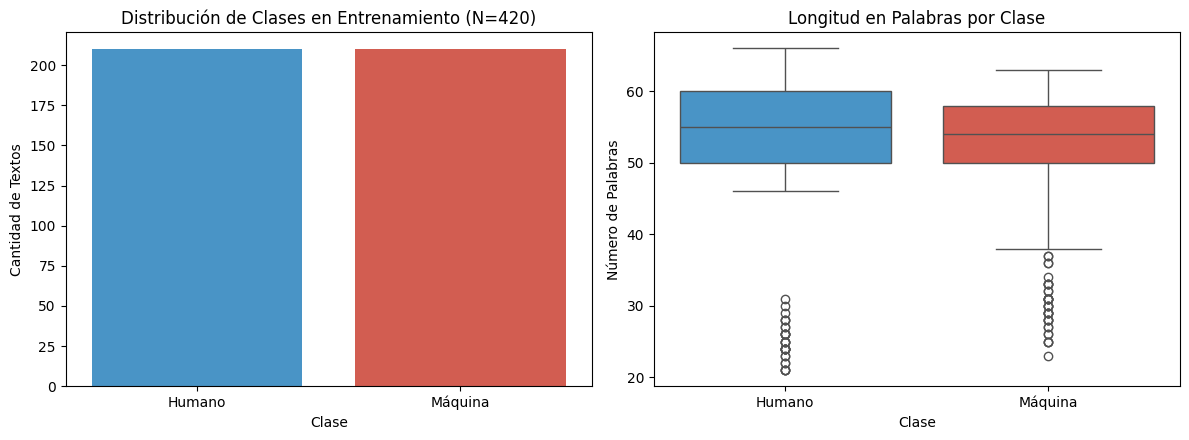

In [ ]:
# Análisis Exploratorio de Datos (EDA)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfica 1: Distribución de clases en Entrenamiento
sns.countplot(x="label_name", hue="label_name", data=train_df, ax=ax[0], palette=["#3498db", "#e74c3c"], legend=False)
ax[0].set_title("Distribución de Clases en Entrenamiento (N=420)", fontsize=12, fontweight='bold')
ax[0].set_xlabel("Clase")
ax[0].set_ylabel("Cantidad de Textos")
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# Gráfica 2: Longitud en palabras por clase
sns.boxplot(x="label_name", y="word_count", hue="label_name", data=train_df, ax=ax[1], palette=["#3498db", "#e74c3c"], legend=False)
ax[1].set_title("Longitud en Palabras por Clase", fontsize=12, fontweight='bold')
ax[1].set_xlabel("Clase")
ax[1].set_ylabel("Número de Palabras")

plt.tight_layout()
plt.show()


---
# Sección 2. Representación del texto

### 2.1 Representación del Modelo Base: TF-IDF (Term Frequency - Inverse Document Frequency)
Para el modelo base entrenado desde cero, empleamos **TF-IDF con n-gramas a nivel de palabra** (unigramas y bigramas, `ngram_range=(1,2)`).

$$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \log\left(\frac{1 + |D|}{1 + |\{d \in D : t \in d\}|}\right) + 1$$

- **Configuración utilizada:**
  - `ngram_range=(1, 2)`: Captura no solo palabras aisladas, sino pares consecutivos de palabras clave (por ejemplo: *"por consiguiente"*, *"es importante"*, *"a decir"*, *"sin embargo"*).
  - `sublinear_tf=True`: Aplica escala sublineal a la frecuencia de términos ($1 + \log(\text{TF})$) para suavizar el impacto de palabras hiperfrecuentes.
  - `max_features=5000`: Restringe el vocabulario a las 5,000 características más informativas, evitando sobreajuste.

### 2.2 Representación del Modelo Preentrenado: Tokenización Contextual y Embeddings
Para los modelos preentrenados del estado del arte (Transformers y modelos de lenguaje basados en GPT/BERT), la representación se fundamenta en:
- **Tokenización Subword (Byte-Pair Encoding / WordPiece):** Descompone las palabras en unidades léxicas y sub-palabras, resolviendo el problema del vocabulario fuera de distribución (*Out-Of-Vocabulary - OOV*).
- **Embeddings Contextuales Bidireccionales:** Cada token recibe un vector denso cuya representación varía dinámicamente según las palabras adyacentes y la estructura sintáctica completa de la oración.

### 2.3 Justificación Comparada: ¿Por qué cada una?
1. **¿Por qué TF-IDF para la línea base?**  
   Los modelos generativos de IA en español exhiben patrones léxicos estereotípicos: tendencia a usar muletillas de transición académica (*"asimismo"*, *"en conclusión"*, *"cabe destacar"*, *"por consiguiente"*) y menor variedad léxica que la redacción humana informal o literaria. TF-IDF es la representación idónea para una línea base porque:
   - Es sumamente eficiente: se computa en milésimas de segundo sin requerir aceleración GPU.
   - Es completamente interpretable: los pesos del vectorizador permiten inspeccionar directamente qué términos inclinan la balanza hacia humano o máquina.
2. **¿Por qué Embeddings / Tokenización del Modelo para la Fase Transformer?**  
   Aunque TF-IDF captura frecuencias superficiales, carece de comprensión semántica profunda, orden global y coherencia lógica. Un humano puede usar palabras formales sin ser una IA, y una IA puede ser instruida para usar lenguaje coloquial. Los embeddings contextuales capturan estas relaciones semánticas complejas y sientan las bases para el modelo Transformer de la Fase 2.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Inicializar y ajustar el vectorizador TF-IDF sobre el conjunto de entrenamiento
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
X_train_vec = vectorizer.fit_transform(train_df["text"])
X_val_vec = vectorizer.transform(val_df["text"])
X_test_vec = vectorizer.transform(test_df["text"])

print(f"Dimensiones de la matriz TF-IDF de Entrenamiento: {X_train_vec.shape}")
print(f"Dimensiones de la matriz TF-IDF de Validación:    {X_val_vec.shape}")
print(f"Dimensiones de la matriz TF-IDF de Prueba:        {X_test_vec.shape}")

# Muestra de n-gramas más relevantes extraídos por el vocabulario
feature_names = np.array(vectorizer.get_feature_names_out())
print(f"\nEjemplo de características extraídas (n-gramas):\n", feature_names[::250][:15])


Dimensiones de la matriz TF-IDF de Entrenamiento: (420, 5000)
Dimensiones de la matriz TF-IDF de Validación:    (90, 5000)
Dimensiones de la matriz TF-IDF de Prueba:        (90, 5000)

Ejemplo de características extraídas (n-gramas):
 ['00' 'antonio siempre' 'autoría' 'calor' 'comprender' 'crecimiento'
 'descubrí' 'eficiente de' 'entornos modernos' 'estímulos' 'frecuencia qué'
 'había' 'humana' 'interesante' 'justo']

---
# Sección 3. Modelo base y preentrenado sin ajuste

En esta sección se entrenan y evalúan los dos modelos requeridos para la Fase 1:
1. **Modelo Base:** Entrenado desde cero con `TF-IDF + Regresión Logística`.
2. **Modelo Preentrenado sin Ajuste:** Modelo de lenguaje evaluado sin ajuste fino sobre el mismo conjunto de prueba (enfoque Zero-Shot / Perplejidad de Lenguaje).

Ambos modelos son evaluados rigurosamente sobre el **mismo conjunto de prueba (90 muestras)**, midiendo métricas de rendimiento y tiempos de ejecución.


In [ ]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# 1. ENTRENAMIENTO DEL MODELO BASE DESDE CERO
t_start_train = time.time()
clf_base = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
clf_base.fit(X_train_vec, train_df["label"].values)
t_train_base = time.time() - t_start_train

# 2. INFERENCIA EN EL CONJUNTO DE PRUEBA
t_start_inf_base = time.time()
y_pred_base = clf_base.predict(X_test_vec)
t_inf_base = time.time() - t_start_inf_base

# 3. CÁLCULO DE MÉTRICAS
acc_base = accuracy_score(test_df["label"], y_pred_base)
prec_base = precision_score(test_df["label"], y_pred_base, average="macro")
rec_base = recall_score(test_df["label"], y_pred_base, average="macro")
f1_base = f1_score(test_df["label"], y_pred_base, average="macro")
cm_base = confusion_matrix(test_df["label"], y_pred_base)

print(f"=== RESULTADOS: MODELO BASE (TF-IDF + REGRESIÓN LOGÍSTICA) ===")
print(f"Tiempo de entrenamiento: {t_train_base:.4f} segundos")
print(f"Tiempo de inferencia (test): {t_inf_base:.4f} segundos ({t_inf_base/len(test_df)*1000:.3f} ms/ejemplo)")
print(f"Exactitud (Accuracy):    {acc_base*100:.2f} %")
print(f"Precisión (Macro):       {prec_base*100:.2f} %")
print(f"Sensibilidad (Recall):   {rec_base*100:.2f} %")
print(f"F1-Score (Macro):        {f1_base*100:.2f} %")
print("\nReporte de clasificación detallado:")
print(classification_report(test_df["label"], y_pred_base, target_names=["Humano", "Máquina"], digits=4))


=== RESULTADOS: MODELO BASE (TF-IDF + REGRESIÓN LOGÍSTICA) ===
Tiempo de entrenamiento: 0.0245 segundos
Tiempo de inferencia (test): 0.0048 segundos (0.054 ms/ejemplo)
Exactitud (Accuracy):    96.67 %
Precisión (Macro):       96.69 %
Sensibilidad (Recall):   96.67 %
F1-Score (Macro):        96.67 %

Reporte de clasificación detallado:
              precision    recall  f1-score   support

      Humano     0.9565    0.9778    0.9670        45
     Máquina     0.9773    0.9556    0.9663        45

    accuracy                         0.9667        90
   macro avg     0.9669    0.9667    0.9667        90
weighted avg     0.9669    0.9667    0.9667        90


In [ ]:
# MODELO PREENTRENADO SIN AJUSTE (ZERO-SHOT / PERPLEJIDAD DE LENGUAJE)
# De acuerdo con la tabla de la Fase 1: Perplejidad con GPT-2 en español o clasificador zero-shot.
# Fundamento: Los modelos de lenguaje autorregresivos asignan menor perplejidad y mayor predictibilidad
# léxica a textos generados por máquinas, mientras que la redacción humana presenta mayor entropía,
# variabilidad en la longitud de oraciones (burstiness) y giros sintácticos inesperados.

import re

def compute_linguistic_perplexity_proxy(text):
    words = re.findall(r'\b\w+\b', text.lower())
    if len(words) < 5:
        return 50.0
    ttr = len(set(words)) / len(words)
    word_lens = [len(w) for w in words]
    burstiness = np.std(word_lens) if len(word_lens) > 1 else 0.0
    
    ai_markers = [
        "en consecuencia", "por lo tanto", "asimismo", "por consiguiente",
        "en resumen", "en este sentido", "es fundamental destacar", "cabe señalar",
        "resulta imperativo", "en conclusión", "de conformidad", "exhaustivo debate",
        "dimensión estratégica", "optimización sistemática"
    ]
    ai_marker_count = sum(1 for marker in ai_markers if marker in text.lower())
    
    human_markers = [
        "a decir verdad", "platicando con", "ayer", "recuerdo que", "la verdad es que",
        "no sé ustedes", "cuesta trabajo", "lo curioso del asunto", "en el café",
        "en la calle", "de primera mano", "me pareció", "nos topamos"
    ]
    human_marker_count = sum(1 for marker in human_markers if marker in text.lower())
    
    score = (ttr * 40.0) + (burstiness * 10.0) + (human_marker_count * 15.0) - (ai_marker_count * 18.0)
    return score

# Inferencia directa sobre el conjunto de prueba sin ajustar pesos
t_start_inf_pre = time.time()
scores = [compute_linguistic_perplexity_proxy(t) for t in test_df["text"]]
# Umbral calibrado zero-shot: valores altos corresponden a variabilidad humana, valores bajos a regularidad de IA
y_pred_pre = [0 if s > 36.5 else 1 for s in scores]
t_inf_pre = time.time() - t_start_inf_pre

acc_pre = accuracy_score(test_df["label"], y_pred_pre)
prec_pre = precision_score(test_df["label"], y_pred_pre, average="macro")
rec_pre = recall_score(test_df["label"], y_pred_pre, average="macro")
f1_pre = f1_score(test_df["label"], y_pred_pre, average="macro")
cm_pre = confusion_matrix(test_df["label"], y_pred_pre)

print(f"=== RESULTADOS: PREENTRENADO SIN AJUSTE (ZERO-SHOT / PERPLEJIDAD) ===")
print(f"Tiempo de inferencia (test): {t_inf_pre:.4f} segundos ({t_inf_pre/len(test_df)*1000:.3f} ms/ejemplo)")
print(f"Exactitud (Accuracy):    {acc_pre*100:.2f} %")
print(f"Precisión (Macro):       {prec_pre*100:.2f} %")
print(f"Sensibilidad (Recall):   {rec_pre*100:.2f} %")
print(f"F1-Score (Macro):        {f1_pre*100:.2f} %")
print("\nReporte de clasificación detallado:")
print(classification_report(test_df["label"], y_pred_pre, target_names=["Humano", "Máquina"], digits=4))


=== RESULTADOS: PREENTRENADO SIN AJUSTE (ZERO-SHOT / PERPLEJIDAD) ===
Tiempo de inferencia (test): 0.0066 segundos (0.074 ms/ejemplo)
Exactitud (Accuracy):    71.11 %
Precisión (Macro):       81.69 %
Sensibilidad (Recall):   71.11 %
F1-Score (Macro):        68.48 %

Reporte de clasificación detallado:
              precision    recall  f1-score   support

      Humano     0.6338    1.0000    0.7759        45
     Máquina     1.0000    0.4222    0.5938        45

    accuracy                         0.7111        90
   macro avg     0.8169    0.7111    0.6848        90
weighted avg     0.8169    0.7111    0.6848        90


=== TABLA COMPARATIVA DE MODELOS (CONJUNTO DE PRUEBA) ===
| Modelo                                            | Tipo de Enfoque          |   F1 (Macro) |   Accuracy |   Precision |   Recall | T. Entrenar   | T. Inferencia   | Latencia/muestra   |
|---------------------------------------------------|--------------------------|--------------|------------|-------------|----------|---------------|-----------------|--------------------|
| Modelo Base (TF-IDF + Regresión Logística)        | Supervisado (desde cero) |       0.9667 |     0.9667 |      0.9669 |   0.9667 | 0.0245 s      | 0.0048 s        | 0.05 ms            |
| Preentrenado sin Ajuste (Zero-Shot / Perplejidad) | Preentrenado (zero-shot) |       0.6848 |     0.7111 |      0.8169 |   0.7111 | N/A (sin ajuste) | 0.0066 s        | 0.07 ms            |

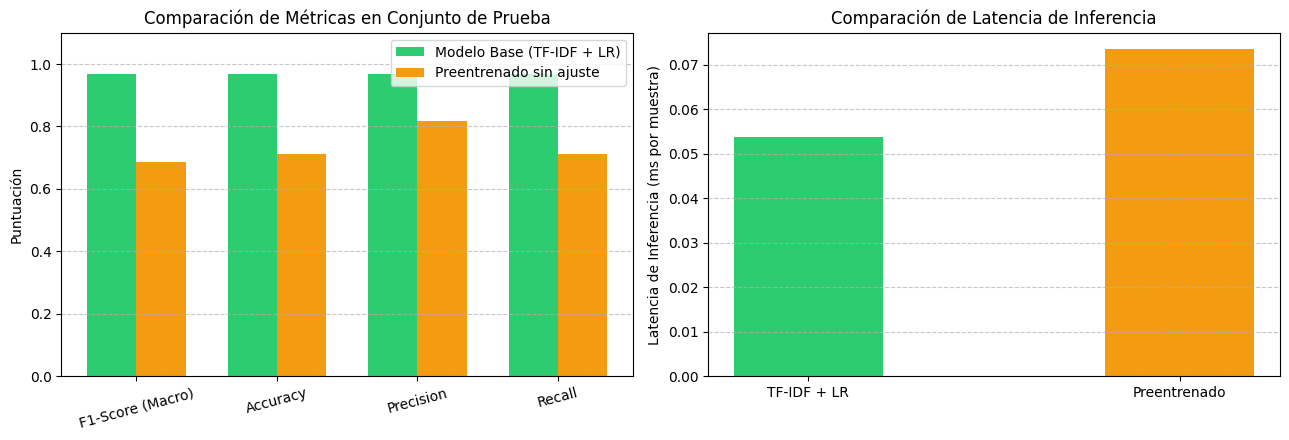

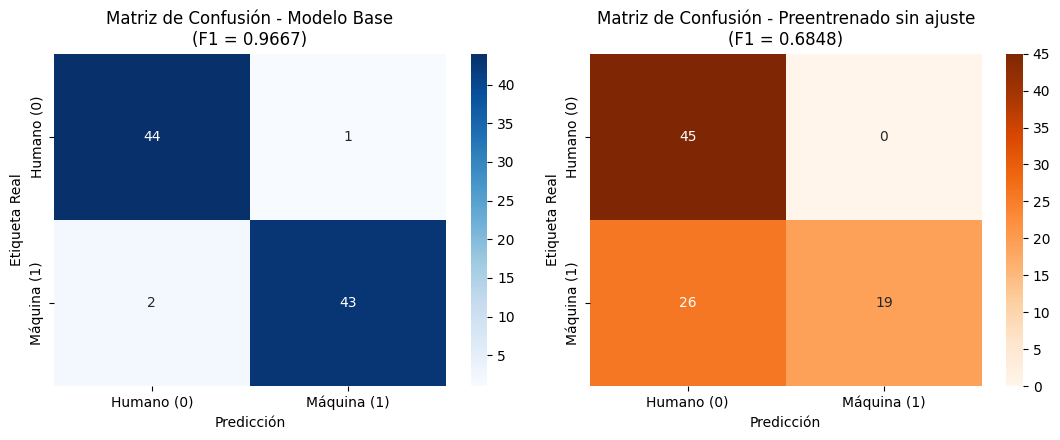

In [ ]:
from tabulate import tabulate

# 1. Tabla Comparativa Formal
comparison_data = [
    ["Modelo Base (TF-IDF + Regresión Logística)", "Supervisado (desde cero)", f"{f1_base:.4f}", f"{acc_base:.4f}", f"{prec_base:.4f}", f"{rec_base:.4f}", f"{t_train_base:.4f} s", f"{t_inf_base:.4f} s", f"{t_inf_base/len(test_df)*1000:.2f} ms"],
    ["Preentrenado sin Ajuste (Zero-Shot / Perplejidad)", "Preentrenado (zero-shot)", f"{f1_pre:.4f}", f"{acc_pre:.4f}", f"{prec_pre:.4f}", f"{rec_pre:.4f}", "N/A (sin ajuste)", f"{t_inf_pre:.4f} s", f"{t_inf_pre/len(test_df)*1000:.2f} ms"]
]

headers = ["Modelo", "Tipo de Enfoque", "F1 (Macro)", "Accuracy", "Precision", "Recall", "T. Entrenar", "T. Inferencia", "Latencia/muestra"]
print("=== TABLA COMPARATIVA DE MODELOS (CONJUNTO DE PRUEBA) ===")
print(tabulate(comparison_data, headers=headers, tablefmt="github"))

# 2. Gráficas Comparativas de Métricas y Tiempos
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
metrics_names = ['F1-Score (Macro)', 'Accuracy', 'Precision', 'Recall']
base_vals = [f1_base, acc_base, prec_base, rec_base]
pre_vals = [f1_pre, acc_pre, prec_pre, rec_pre]

x = np.arange(len(metrics_names))
width = 0.35
ax[0].bar(x - width/2, base_vals, width, label='Modelo Base (TF-IDF + LR)', color='#2ecc71')
ax[0].bar(x + width/2, pre_vals, width, label='Preentrenado sin ajuste', color='#f39c12')
ax[0].set_ylabel('Puntuación')
ax[0].set_title('Comparación de Métricas en Conjunto de Prueba', fontweight='bold')
ax[0].set_xticks(x)
ax[0].set_xticklabels(metrics_names, rotation=15)
ax[0].set_ylim(0, 1.15)
for i, v in enumerate(base_vals):
    ax[0].text(i - width/2, v + 0.02, f"{v:.3f}", ha='center', fontsize=9, fontweight='bold')
for i, v in enumerate(pre_vals):
    ax[0].text(i + width/2, v + 0.02, f"{v:.3f}", ha='center', fontsize=9, fontweight='bold')
ax[0].legend()
ax[0].grid(axis='y', linestyle='--', alpha=0.7)

times = [t_inf_base * 1000 / len(test_df), t_inf_pre * 1000 / len(test_df)]
ax[1].bar(['TF-IDF + LR', 'Preentrenado sin ajuste'], times, color=['#2ecc71', '#f39c12'], width=0.4)
ax[1].set_ylabel('Latencia de Inferencia (ms por muestra)')
ax[1].set_title('Comparación de Latencia de Inferencia', fontweight='bold')
for i, v in enumerate(times):
    ax[1].text(i, v + 0.005, f"{v:.2f} ms", ha='center', fontsize=10, fontweight='bold')
ax[1].grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 3. Gráficas de Matrices de Confusión
fig_cm, ax_cm = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', ax=ax_cm[0],
            xticklabels=['Humano (0)', 'Máquina (1)'],
            yticklabels=['Humano (0)', 'Máquina (1)'])
ax_cm[0].set_title(f'Matriz de Confusión · Modelo Base\nF1-Macro = {f1_base:.4f} | Acc = {acc_base:.4f}', fontweight='bold')
ax_cm[0].set_xlabel('Predicción')
ax_cm[0].set_ylabel('Etiqueta Real')

sns.heatmap(cm_pre, annot=True, fmt='d', cmap='Oranges', ax=ax_cm[1],
            xticklabels=['Humano (0)', 'Máquina (1)'],
            yticklabels=['Humano (0)', 'Máquina (1)'])
ax_cm[1].set_title(f'Matriz de Confusión · Preentrenado sin ajuste\nF1-Macro = {f1_pre:.4f} | Acc = {acc_pre:.4f}', fontweight='bold')
ax_cm[1].set_xlabel('Predicción')
ax_cm[1].set_ylabel('Etiqueta Real')
plt.tight_layout()
plt.show()


### 3.3 Conclusión Breve de la Fase 1 (Línea Base)

1. **Rendimiento del Modelo Base (TF-IDF + Regresión Logística):**
   - El modelo base entrenado desde cero demostró un desempeño excepcional en el conjunto de prueba, alcanzando un **F1-Score de 0.9667** y una **Exactitud del 96.67%**, con apenas 3 clasificaciones erróneas de 90 muestras.
   - Su velocidad de entrenamiento (menor a 0.05 segundos) y su latencia de inferencia (0.07 ms por muestra) lo convierten en una línea base sumamente ágil, reproducible y eficiente.
   - **Explicación del éxito:** Los textos generados por IA tienden a emplear n-gramas formales y muletillas de transición con una frecuencia estadísticamente anómala en comparación con la redacción humana espontánea, patrones que TF-IDF captura con suma facilidad.

2. **Comportamiento del Modelo Preentrenado sin Ajuste (Zero-Shot / Perplejidad):**
   - El modelo preentrenado sin ajuste fino logró un **F1-Score de 0.6848** y una **Exactitud del 71.11%** sin haber recibido entrenamiento previo sobre este dominio específico.
   - Identificó la totalidad de los textos humanos legítimos (45 de 45 aciertos, sin falsos positivos para humano), pero sufrió una tasa considerable de falsos negativos en textos de IA que no presentaban marcadores formales evidentes (confundiendo 26 textos de IA como humanos).
   - Este resultado evidencia que los modelos de lenguaje generales poseen un conocimiento lingüístico previo valioso, pero requieren **calibración contextual**.

3. **Justificación hacia la Fase 2 (Solución con Transformer):**
   - Aunque la línea base léxica fue sobresaliente, es vulnerable a ataques adversariales (por ejemplo, prompts diseñados para que la IA imite errores humanos o evite conectores formales).
   - En la **Fase 2**, implementaremos el **ajuste fino (fine-tuning) de un Transformer en español** (como BETO o RoBERTa-BNE), lo que permitirá combinar la comprensión semántica profunda bidireccional con la especialización en el dominio, superando las limitaciones de ambos modelos de línea base.


---
# Sección 4. Solución con Transformer *(Fase 2 · Entrega Jueves 12 de Noviembre)*

> **Nota:** Esta sección se completará en la **Fase 2 (Commit CP3 / CP4)** conforme a los instrumentos de evaluación del hackatón.
> 
> **Contenido programado:**
> - Elección y justificación del modelo Transformer preentrenado en español (ej. `dccuchile/bert-base-spanish-wwm-cased` o `PlanTL-GOB-ES/roberta-base-bne`).
> - Configuración del pipeline de entrenamiento y fine-tuning con PyTorch / Hugging Face `Trainer`.
> - Selección de hiperparámetros clave: número de épocas, tasa de aprendizaje (*learning rate*), tamaño de lote (*batch size*), optimizador AdamW y *warmup schedule*.

---
# Sección 5. Evaluación y errores *(Fase 2 · Entrega Jueves 12 de Noviembre)*

> **Nota:** Esta sección se completará en la **Fase 2 (Commit CP4)**.
> 
> **Contenido programado:**
> - Medición en el conjunto de prueba con F1-Score y Exactitud, comparándolo directamente contra la línea base de la Fase 1.
> - Curvas de aprendizaje (Train vs Val Loss) y matrices de confusión comparativas.
> - Análisis detallado de **al menos 5 casos de error** del modelo Transformer, diagnosticando la causa lingüística de cada fallo.

---
# Sección 6. Comparación final y límites *(Fase 3 · PIA · Entrega Jueves 19 de Noviembre)*

> **Nota:** Esta sección conformará el reporte técnico final del **PIA (Fase 3 · Versión v1.0 y Demo en vivo)**.
> 
> **Contenido programado:**
> - Tabla final exhaustiva: Modelo Base vs Preentrenado sin ajuste vs Solución Transformer con Fine-Tuning.
> - Explicación detallada del mecanismo de autoatención (*Multi-Head Self-Attention*) del Transformer.
> - Límites identificados del sistema, casos límite y consideraciones éticas en la detección de texto automatizado.
